In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


In [2]:
df = pd.read_csv('/content/Salary_Data.csv')


In [3]:
df.head()

,Age,Gender,Education Level,Job Title,Years of Experience,Salary
0,32.0,Male,Bachelor's,Software Engineer,5.0,90000.0
1,28.0,Female,Master's,Data Analyst,3.0,65000.0
2,45.0,Male,PhD,Senior Manager,15.0,150000.0
3,36.0,Female,Bachelor's,Sales Associate,7.0,60000.0
4,52.0,Male,Master's,Director,20.0,200000.0


In [4]:
df.shape

(6704, 6)

In [5]:
df.columns

Index(['Age', 'Gender', 'Education Level', 'Job Title', 'Years of Experience',
       'Salary'],
      dtype='object')

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
,RangeIndex: 6704 entries, 0 to 6703
,Data columns (total 6 columns):
, #   Column               Non-Null Count  Dtype  
,---  ------               --------------  -----  
, 0   Age                  6702 non-null   float64
, 1   Gender               6702 non-null   object 
, 2   Education Level      6701 non-null   object 
, 3   Job Title            6702 non-null   object 
, 4   Years of Experience  6701 non-null   float64
, 5   Salary               6699 non-null   float64
,dtypes: float64(3), object(3)
,memory usage: 314.4+ KB


In [7]:
df.describe()

,Age,Years of Experience,Salary
count,6702.000000,6701.000000,6699.000000
mean,33.620859,8.094687,115326.964771
std,7.614633,6.059003,52786.183911
min,21.000000,0.000000,350.000000
25%,28.000000,3.000000,70000.000000
50%,32.000000,7.000000,115000.000000
75%,38.000000,12.000000,160000.000000
max,62.000000,34.000000,250000.000000


In [8]:
df.isnull().sum()

,0
Age,2
Gender,2
Education Level,3
Job Title,2
Years of Experience,3
Salary,5


In [9]:
df = df.dropna()

In [10]:
df.isnull().sum()

,0
Age,0
Gender,0
Education Level,0
Job Title,0
Years of Experience,0
Salary,0


In [11]:
df.duplicated().sum()

np.int64(4911)

In [12]:
df = df.drop_duplicates()

In [13]:
df.duplicated().sum()

np.int64(0)

In [14]:
df.shape

(1787, 6)

In [15]:
df.head()

,Age,Gender,Education Level,Job Title,Years of Experience,Salary
0,32.0,Male,Bachelor's,Software Engineer,5.0,90000.0
1,28.0,Female,Master's,Data Analyst,3.0,65000.0
2,45.0,Male,PhD,Senior Manager,15.0,150000.0
3,36.0,Female,Bachelor's,Sales Associate,7.0,60000.0
4,52.0,Male,Master's,Director,20.0,200000.0


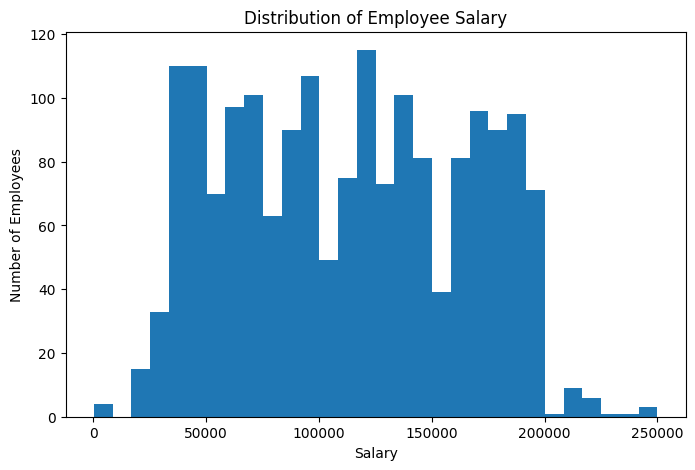

In [16]:
plt.figure(figsize=(8,5))

plt.hist(df['Salary'], bins=30)

plt.xlabel('Salary')
plt.ylabel('Number of Employees')
plt.title('Distribution of Employee Salary')

plt.show()

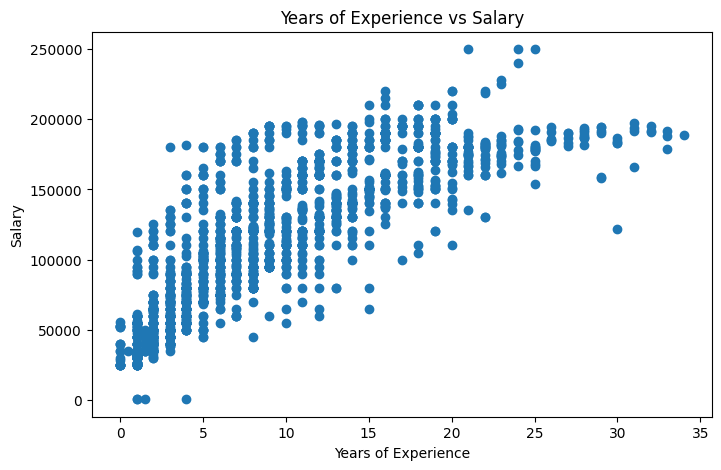

In [17]:
plt.figure(figsize=(8,5))

plt.scatter(
    df['Years of Experience'],
    df['Salary']
)

plt.xlabel('Years of Experience')
plt.ylabel('Salary')
plt.title('Years of Experience vs Salary')

plt.show()

In [18]:
df['Education Level'].unique()

array(["Bachelor's", "Master's", 'PhD', "Bachelor's Degree",
       "Master's Degree", 'High School', 'phD'], dtype=object)

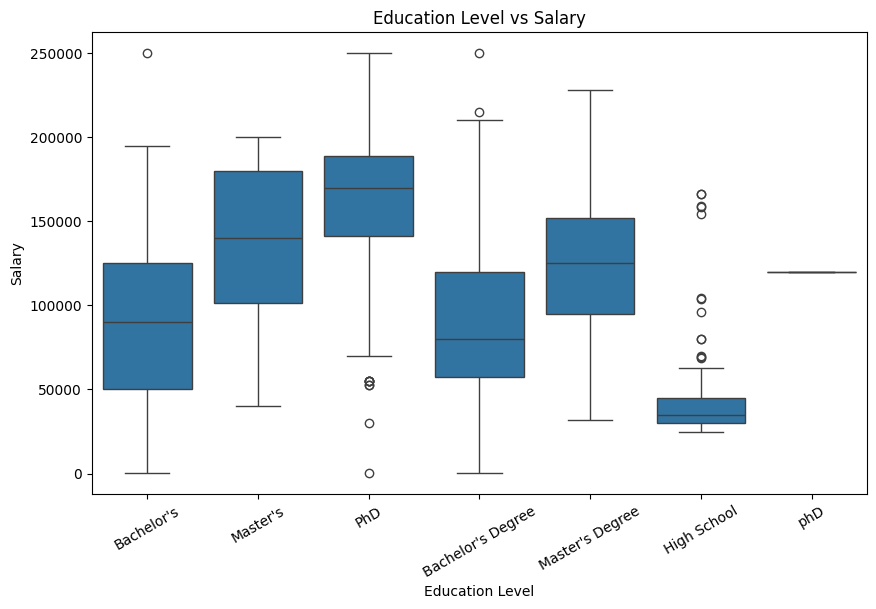

In [19]:
plt.figure(figsize=(10,6))

sns.boxplot(
    x='Education Level',
    y='Salary',
    data=df
)

plt.xticks(rotation=30)

plt.xlabel('Education Level')
plt.ylabel('Salary')

plt.title('Education Level vs Salary')

plt.show()

In [20]:
df[['Age', 'Years of Experience', 'Salary']].corr()

,Age,Years of Experience,Salary
Age,1.000000,0.936260,0.766841
Years of Experience,0.936260,1.000000,0.818725
Salary,0.766841,0.818725,1.000000


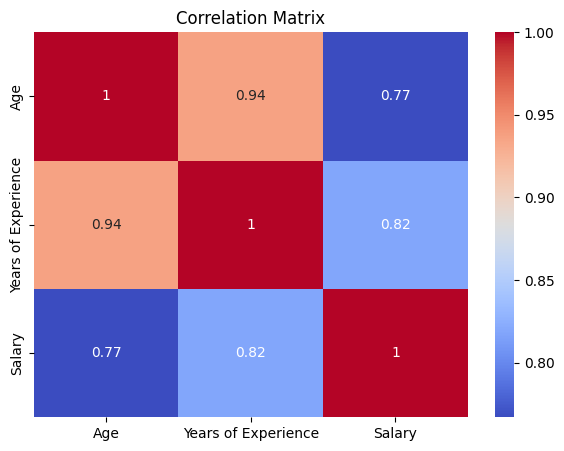

In [21]:
plt.figure(figsize=(7,5))

sns.heatmap(
    df[['Age', 'Years of Experience', 'Salary']].corr(),
    annot=True,
    cmap='coolwarm'
)

plt.title('Correlation Matrix')

plt.show()

In [22]:
X = df.drop('Salary', axis=1)
y = df['Salary']

In [23]:
X.head()

,Age,Gender,Education Level,Job Title,Years of Experience
0,32.0,Male,Bachelor's,Software Engineer,5.0
1,28.0,Female,Master's,Data Analyst,3.0
2,45.0,Male,PhD,Senior Manager,15.0
3,36.0,Female,Bachelor's,Sales Associate,7.0
4,52.0,Male,Master's,Director,20.0


In [24]:
y.head()

,Salary
0,90000.0
1,65000.0
2,150000.0
3,60000.0
4,200000.0


In [25]:
categorical_features = [
    'Gender',
    'Education Level',
    'Job Title'
]

In [26]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            'cat',
            OneHotEncoder(handle_unknown='ignore'),
            categorical_features
        )
    ],
    remainder='passthrough'
)

In [27]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

In [28]:
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (1429, 5)
,Testing data: (358, 5)


In [29]:
model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('regressor', RandomForestRegressor(
            n_estimators=200,
            random_state=42
        ))
    ]
)

In [30]:
model.fit(X_train, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/compose/_column_transformer.py:1667: FutureWarning: 
,The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
,At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configuration, in the future they will be stored as column names (of type str).
,To use the new behavior now and suppress this warning, use ColumnTransformer(force_int_remainder_cols=False).
,
,  warnings.warn(


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Gender', 'Education Level',
                                                   'Job Title'])])),
                ('regressor',
                 RandomForestRegressor(n_estimators=200, random_state=42))])

In [31]:
y_pred = model.predict(X_test)

In [32]:
print(y_pred[:10])


[133808.52        55352.81833333  25716.66666667  93075.
, 137590.68       151604.06691667 155006.79       113799.82125
,  47159.16666667  44745.        ]


In [33]:
mae = mean_absolute_error(y_test, y_pred)

print("Mean Absolute Error:", mae)

Mean Absolute Error: 9715.325771558128


In [34]:
mse = mean_squared_error(y_test, y_pred)

print("Mean Squared Error:", mse)

Mean Squared Error: 232220046.58864266


In [35]:
rmse = np.sqrt(mse)

print("Root Mean Squared Error:", rmse)

Root Mean Squared Error: 15238.767882891407


In [36]:
r2 = r2_score(y_test, y_pred)

print("R² Score:", r2)

R² Score: 0.9152463117593295


In [37]:
print("Model Evaluation")
print("-------------------------")

print("MAE  :", mae)
print("MSE  :", mse)
print("RMSE :", rmse)
print("R²   :", r2)

Model Evaluation
,-------------------------
,MAE  : 9715.325771558128
,MSE  : 232220046.58864266
,RMSE : 15238.767882891407
,R²   : 0.9152463117593295


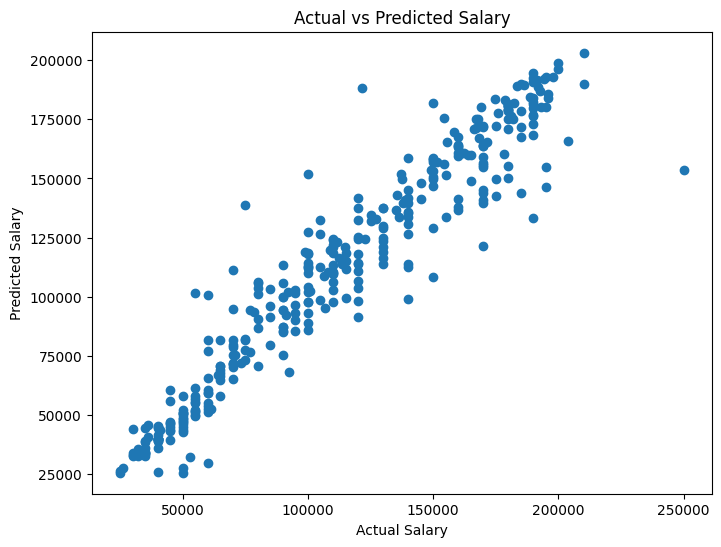

In [38]:
plt.figure(figsize=(8,6))

plt.scatter(y_test, y_pred)

plt.xlabel('Actual Salary')
plt.ylabel('Predicted Salary')

plt.title('Actual vs Predicted Salary')

plt.show()

In [39]:
results = pd.DataFrame({
    'Actual Salary': y_test.values,
    'Predicted Salary': y_pred
})

results.head(10)

,Actual Salary,Predicted Salary
0,155000.0,133808.520000
1,55000.0,55352.818333
2,50000.0,25716.666667
3,95000.0,93075.000000
4,130000.0,137590.680000
5,154990.0,151604.066917
6,170000.0,155006.790000
7,120000.0,113799.821250
8,50000.0,47159.166667
9,40000.0,44745.000000
